# Comparación: mejor NN de `05` vs mejor árbol de `04`

Este notebook compara directamente:

- el mejor árbol encontrado en `04_xgboost_v2_vs_i123.ipynb`
- el mejor modelo de red neuronal reentrenado en `05_best_optuna_nn_on_v2_nn_dense.ipynb`

La comparación se hace a partir de los CSV ya exportados por ambos notebooks.


In [1]:
from __future__ import annotations

from pathlib import Path
import os

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import matplotlib.pyplot as plt
from IPython.display import display
import pandas as pd

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 200)


def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "roadmap.md").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("No se pudo localizar la raíz del proyecto.")


In [2]:
project_root = find_project_root()
results_dir = project_root / "10.try" / "results"

tree_comparison_path = results_dir / "xgboost_v2_vs_i123_comparison.csv"
nn_comparison_path = results_dir / "nn_best_optuna_on_v2_nn_dense_comparison.csv"

if not tree_comparison_path.exists():
    raise FileNotFoundError(f"Falta el resultado de 04: {tree_comparison_path}")
if not nn_comparison_path.exists():
    raise FileNotFoundError(f"Falta el resultado de 05: {nn_comparison_path}")

tree_df = pd.read_csv(tree_comparison_path)
nn_df = pd.read_csv(nn_comparison_path)

best_tree_row = tree_df.iloc[0].copy()
best_nn_row = nn_df.loc[nn_df["dataset"] == "v2_nn_dense_best_optuna"].iloc[0].copy()

print("Mejor árbol tomado de 04:")
display(pd.DataFrame([best_tree_row]).round(4))
print("Mejor NN tomado de 05:")
display(pd.DataFrame([best_nn_row]).round(4))


Mejor árbol tomado de 04:


,dataset,result_origin,source,accuracy,precision,recall,f1,auc,ams,ams_threshold,fit_seconds,feature_count,train_nan_count,valid_nan_count,delta_auc_vs_best_notebook,delta_ams_vs_best_notebook,delta_auc_vs_i3_notebook,delta_ams_vs_i2_notebook
0,v2_physics_by_jet,trained_in_10_try,same_best_xgboost_as_7_arboles,0.8361,0.7436,0.7963,0.7691,0.9099,1.1079,0.9049,6.4865,86,0,0,0.0006,0.0211,0.0006,0.0211


Mejor NN tomado de 05:


,dataset,source,n_hidden,n_units,learning_rate,batch_size,first_layer_wider,epochs_ran,loss,accuracy,auc,precision,recall,ams,ams_threshold,signal_weight,background_weight,candidate_threshold_count,delta_loss_vs_i1_best_optuna,delta_accuracy_vs_i1_best_optuna,delta_auc_vs_i1_best_optuna,delta_precision_vs_i1_best_optuna,delta_recall_vs_i1_best_optuna
1,v2_nn_dense_best_optuna,10.try/02 + best_optuna_architecture,2,160,0.0009,256,True,16,0.3841,0.8258,0.9081,0.7111,0.8283,1.0924,0.9353,16.4625,211.6688,24989.0,-0.0081,0.0044,0.0031,0.0086,-0.0021


In [3]:
comparison_rows = [
    {
        "model_family": "tree",
        "dataset": str(best_tree_row["dataset"]),
        "source": str(best_tree_row["source"]),
        "loss": pd.NA,
        "accuracy": float(best_tree_row["accuracy"]),
        "precision": float(best_tree_row["precision"]),
        "recall": float(best_tree_row["recall"]),
        "f1": float(best_tree_row["f1"]),
        "auc": float(best_tree_row["auc"]),
        "ams": float(best_tree_row["ams"]),
        "ams_threshold": float(best_tree_row["ams_threshold"]),
    },
    {
        "model_family": "nn",
        "dataset": str(best_nn_row["dataset"]),
        "source": str(best_nn_row["source"]),
        "loss": float(best_nn_row["loss"]),
        "accuracy": float(best_nn_row["accuracy"]),
        "precision": float(best_nn_row["precision"]),
        "recall": float(best_nn_row["recall"]),
        "f1": pd.NA,
        "auc": float(best_nn_row["auc"]),
        "ams": float(best_nn_row["ams"]),
        "ams_threshold": float(best_nn_row["ams_threshold"]),
    },
]

comparison_df = pd.DataFrame(comparison_rows)
reference_tree = comparison_df.loc[comparison_df["model_family"] == "tree"].iloc[0]

for metric in ["accuracy", "precision", "recall", "auc", "ams"]:
    comparison_df[f"delta_{metric}_vs_tree"] = comparison_df[metric] - float(reference_tree[metric])

if pd.notna(reference_tree["f1"]):
    comparison_df["delta_f1_vs_tree"] = comparison_df["f1"].astype("Float64") - float(reference_tree["f1"])
else:
    comparison_df["delta_f1_vs_tree"] = pd.NA

ordered_columns = [
    "model_family",
    "dataset",
    "source",
    "loss",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "auc",
    "ams",
    "ams_threshold",
    "delta_accuracy_vs_tree",
    "delta_precision_vs_tree",
    "delta_recall_vs_tree",
    "delta_f1_vs_tree",
    "delta_auc_vs_tree",
    "delta_ams_vs_tree",
]

print("Comparación directa árbol vs NN:")
display(comparison_df[ordered_columns].round(4))


Comparación directa árbol vs NN:


,model_family,dataset,source,loss,accuracy,precision,recall,f1,auc,ams,ams_threshold,delta_accuracy_vs_tree,delta_precision_vs_tree,delta_recall_vs_tree,delta_f1_vs_tree,delta_auc_vs_tree,delta_ams_vs_tree
0,tree,v2_physics_by_jet,same_best_xgboost_as_7_arboles,<NA>,0.8361,0.7436,0.7963,0.769066,0.9099,1.1079,0.9049,0.0000,0.0000,0.000,0.0,0.0000,0.0000
1,nn,v2_nn_dense_best_optuna,10.try/02 + best_optuna_architecture,0.384117,0.8258,0.7111,0.8283,<NA>,0.9081,1.0924,0.9353,-0.0103,-0.0325,0.032,<NA>,-0.0018,-0.0154


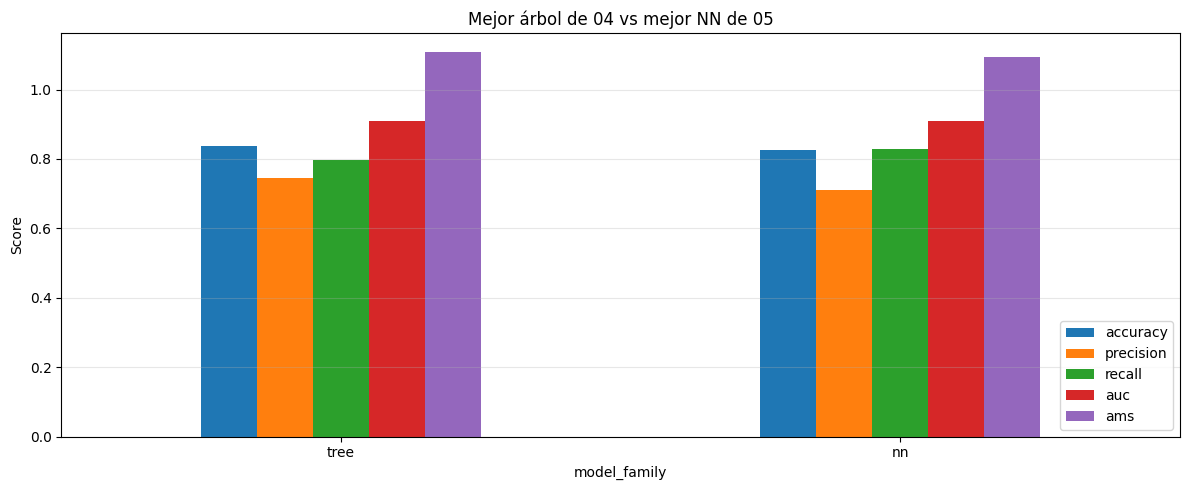

In [4]:
plot_metrics = ["accuracy", "precision", "recall", "auc", "ams"]
plot_df = comparison_df.set_index("model_family")[plot_metrics]
plot_df.plot(kind="bar", figsize=(12, 5), rot=0)
plt.ylabel("Score")
plt.title("Mejor árbol de 04 vs mejor NN de 05")
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [5]:
summary_txt_path = results_dir / "best_nn_vs_best_tree_summary.txt"
comparison_csv_path = results_dir / "best_nn_vs_best_tree_comparison.csv"
comparison_df.to_csv(comparison_csv_path, index=False)

winner_auc = comparison_df.sort_values("auc", ascending=False).iloc[0]
winner_ams = comparison_df.sort_values("ams", ascending=False).iloc[0]

summary_lines = [
    "# Comparación mejor NN vs mejor árbol",
    "",
    f"Mejor árbol: {best_tree_row['dataset']} ({best_tree_row['source']})",
    f"- accuracy={float(best_tree_row['accuracy']):.6f}",
    f"- precision={float(best_tree_row['precision']):.6f}",
    f"- recall={float(best_tree_row['recall']):.6f}",
    f"- f1={float(best_tree_row['f1']):.6f}",
    f"- auc={float(best_tree_row['auc']):.6f}",
    f"- ams={float(best_tree_row['ams']):.6f}",
    "",
    f"Mejor NN: {best_nn_row['dataset']} ({best_nn_row['source']})",
    f"- loss={float(best_nn_row['loss']):.6f}",
    f"- accuracy={float(best_nn_row['accuracy']):.6f}",
    f"- precision={float(best_nn_row['precision']):.6f}",
    f"- recall={float(best_nn_row['recall']):.6f}",
    f"- auc={float(best_nn_row['auc']):.6f}",
    f"- ams={float(best_nn_row['ams']):.6f}",
    "",
    f"Ganador por AUC: {winner_auc['model_family']} ({winner_auc['dataset']}) con {winner_auc['auc']:.6f}",
    f"Ganador por AMS: {winner_ams['model_family']} ({winner_ams['dataset']}) con {winner_ams['ams']:.6f}",
    "",
    f"CSV guardado en: {comparison_csv_path}",
]
summary_txt_path.write_text("\n".join(summary_lines) + "\n")

print(f"CSV comparativo guardado en: {comparison_csv_path}")
print(f"Resumen textual guardado en: {summary_txt_path}")


CSV comparativo guardado en: /home/santig14/fing/taa/1_TallerAA/10.try/results/best_nn_vs_best_tree_comparison.csv
Resumen textual guardado en: /home/santig14/fing/taa/1_TallerAA/10.try/results/best_nn_vs_best_tree_summary.txt
